In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

dataset_path = Path(
    "../data/processed/airfoil_dataset_final.csv"
)

data = pd.read_csv(dataset_path)

print("Dataset rows:", len(data))
print("Airfoils:", data["airfoil"].nunique())
print("Reynolds numbers:", sorted(data["reynolds"].unique()))

data.head()

Dataset rows: 1925
Airfoils: 21
Reynolds numbers: [np.int64(100000), np.int64(200000), np.int64(300000), np.int64(400000), np.int64(500000)]


,airfoil,max_camber,camber_position,thickness,reynolds,alpha,CL,CD,CDp,CM,Top_Xtr,Bot_Xtr
0,NACA 0009,0.0,0.0,0.09,100000,-6.0,-0.6487,0.02375,0.01398,-0.0061,1.0,0.0936
1,NACA 0009,0.0,0.0,0.09,100000,-5.0,-0.5577,0.01810,0.00868,-0.0021,1.0,0.1563
2,NACA 0009,0.0,0.0,0.09,100000,-4.0,-0.4836,0.01363,0.00614,0.0047,1.0,0.4891
3,NACA 0009,0.0,0.0,0.09,100000,-3.0,-0.4028,0.01237,0.00578,0.0140,1.0,0.7572
4,NACA 0009,0.0,0.0,0.09,100000,-2.0,-0.2703,0.01300,0.00629,0.0153,1.0,0.9335


In [4]:
features = [
    "max_camber",
    "camber_position",
    "thickness",
    "reynolds",
    "alpha",
]

targets = [
    "CL",
    "CD",
]

X = data[features]
y = data[targets]

print("Input variables:")
print(features)

print("\nOutput variables:")
print(targets)

print("\nInput shape:", X.shape)
print("Output shape:", y.shape)

Input variables:
['max_camber', 'camber_position', 'thickness', 'reynolds', 'alpha']

Output variables:
['CL', 'CD']

Input shape: (1925, 5)
Output shape: (1925, 2)


In [5]:
test_airfoils = [
    "NACA 0012",
    "NACA 2412",
    "NACA 4412",
]

train_data = data[
    ~data["airfoil"].isin(test_airfoils)
].copy()

test_data = data[
    data["airfoil"].isin(test_airfoils)
].copy()

print("Training airfoils:")
print(train_data["airfoil"].nunique())

print("\nTest airfoils:")
print(test_data["airfoil"].unique())

print("\nTraining rows:", len(train_data))
print("Test rows:", len(test_data))

Training airfoils:
18

Test airfoils:
<StringArray>
['NACA 0012', 'NACA 2412', 'NACA 4412']
Length: 3, dtype: str

Training rows: 1644
Test rows: 281


In [6]:
X_train = train_data[features]
X_test = test_data[features]

y_train_CL = train_data["CL"]
y_test_CL = test_data["CL"]

y_train_CD = train_data["CD"]
y_test_CD = test_data["CD"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (1644, 5)
X_test: (281, 5)


In [7]:
cl_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", LinearRegression()),
])

cd_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", LinearRegression()),
])

cl_model.fit(
    X_train,
    y_train_CL,
)

cd_model.fit(
    X_train,
    y_train_CD,
)

print("Baseline models trained successfully.")

Baseline models trained successfully.


In [8]:
CL_pred = cl_model.predict(
    X_test
)

CD_pred = cd_model.predict(
    X_test
)

print("Predictions complete.")

print(
    "CL predictions:",
    len(CL_pred)
)

print(
    "CD predictions:",
    len(CD_pred)
)

Predictions complete.
CL predictions: 281
CD predictions: 281


In [9]:
CL_MAE = mean_absolute_error(
    y_test_CL,
    CL_pred,
)

CL_RMSE = np.sqrt(
    mean_squared_error(
        y_test_CL,
        CL_pred,
    )
)

CL_R2 = r2_score(
    y_test_CL,
    CL_pred,
)


CD_MAE = mean_absolute_error(
    y_test_CD,
    CD_pred,
)

CD_RMSE = np.sqrt(
    mean_squared_error(
        y_test_CD,
        CD_pred,
    )
)

CD_R2 = r2_score(
    y_test_CD,
    CD_pred,
)


print("BASELINE MODEL RESULTS")
print("----------------------")

print("\nLift coefficient:")
print(f"MAE  = {CL_MAE:.5f}")
print(f"RMSE = {CL_RMSE:.5f}")
print(f"R²   = {CL_R2:.5f}")

print("\nDrag coefficient:")
print(f"MAE  = {CD_MAE:.5f}")
print(f"RMSE = {CD_RMSE:.5f}")
print(f"R²   = {CD_R2:.5f}")

BASELINE MODEL RESULTS
----------------------

Lift coefficient:
MAE  = 0.07339
RMSE = 0.09216
R²   = 0.97616

Drag coefficient:
MAE  = 0.00615
RMSE = 0.00846
R²   = 0.32673


In [10]:
predictions = test_data.copy()

predictions["CL_pred"] = CL_pred
predictions["CD_pred"] = CD_pred

predictions["CL_error"] = (
    predictions["CL"]
    - predictions["CL_pred"]
)

predictions["CD_error"] = (
    predictions["CD"]
    - predictions["CD_pred"]
)

predictions[
    [
        "airfoil",
        "reynolds",
        "alpha",
        "CL",
        "CL_pred",
        "CD",
        "CD_pred",
    ]
].head(10)

,airfoil,reynolds,alpha,CL,CL_pred,CD,CD_pred
73,NACA 0012,100000,-6.0,-0.6863,-0.668598,0.01958,0.018540
74,NACA 0012,100000,-5.0,-0.6142,-0.567084,0.01674,0.019300
75,NACA 0012,100000,-4.0,-0.5366,-0.465570,0.01519,0.020060
76,NACA 0012,100000,-3.0,-0.4545,-0.364056,0.01440,0.020820
77,NACA 0012,100000,-2.0,-0.3737,-0.262542,0.01444,0.021579
78,NACA 0012,100000,-1.0,-0.2578,-0.161028,0.01574,0.022339
79,NACA 0012,100000,0.0,0.0000,-0.059514,0.01694,0.023099
80,NACA 0012,100000,1.0,0.2578,0.042001,0.01574,0.023858
81,NACA 0012,100000,2.0,0.3736,0.143515,0.01444,0.024618
82,NACA 0012,100000,3.0,0.4545,0.245029,0.01440,0.025378


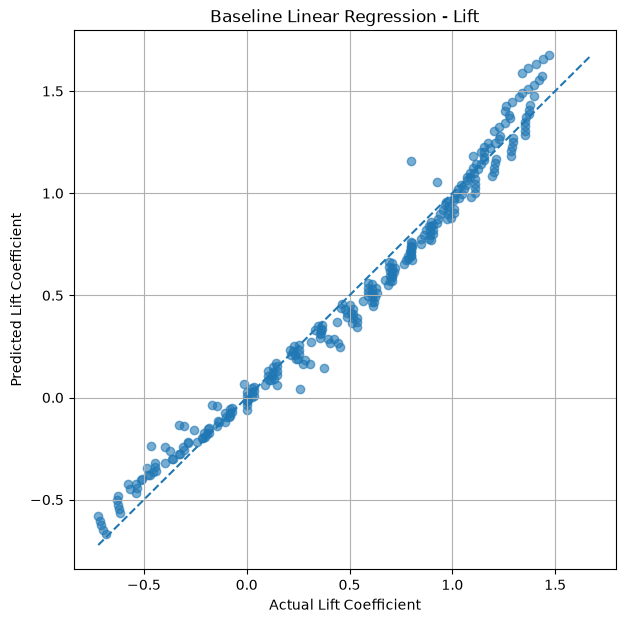

In [11]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_test_CL,
    CL_pred,
    alpha=0.6,
)

minimum = min(
    y_test_CL.min(),
    CL_pred.min(),
)

maximum = max(
    y_test_CL.max(),
    CL_pred.max(),
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
)

plt.xlabel("Actual Lift Coefficient")
plt.ylabel("Predicted Lift Coefficient")

plt.title(
    "Baseline Linear Regression - Lift"
)

plt.grid()

plt.show()

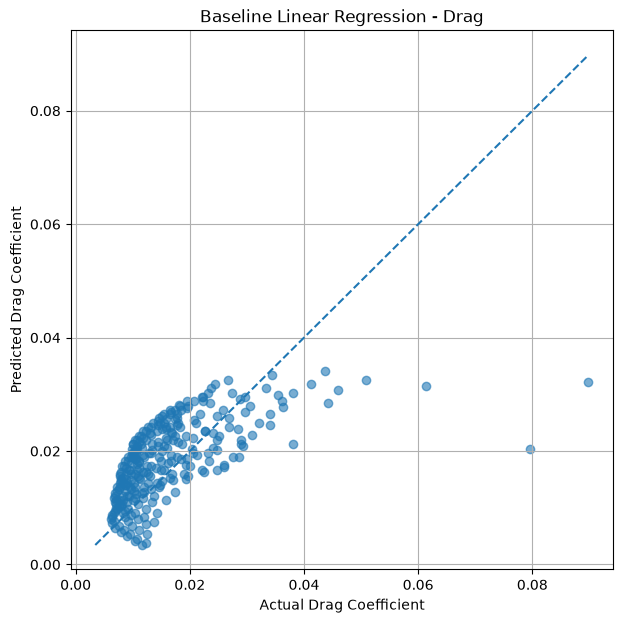

In [12]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_test_CD,
    CD_pred,
    alpha=0.6,
)

minimum = min(
    y_test_CD.min(),
    CD_pred.min(),
)

maximum = max(
    y_test_CD.max(),
    CD_pred.max(),
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
)

plt.xlabel("Actual Drag Coefficient")
plt.ylabel("Predicted Drag Coefficient")

plt.title(
    "Baseline Linear Regression - Drag"
)

plt.grid()

plt.show()

In [13]:
for airfoil in test_airfoils:

    subset = predictions[
        predictions["airfoil"]
        == airfoil
    ]

    cl_mae = mean_absolute_error(
        subset["CL"],
        subset["CL_pred"],
    )

    cd_mae = mean_absolute_error(
        subset["CD"],
        subset["CD_pred"],
    )

    print(airfoil)

    print(
        f"  CL MAE = {cl_mae:.5f}"
    )

    print(
        f"  CD MAE = {cd_mae:.5f}"
    )

    print()

NACA 0012
  CL MAE = 0.07869
  CD MAE = 0.00606

NACA 2412
  CL MAE = 0.06870
  CD MAE = 0.00557

NACA 4412
  CL MAE = 0.07271
  CD MAE = 0.00684



In [14]:
from sklearn.preprocessing import PolynomialFeatures

In [15]:
cl_poly_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "poly",
        PolynomialFeatures(
            degree=2,
            include_bias=False,
        ),
    ),
    ("regression", LinearRegression()),
])


cd_poly_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "poly",
        PolynomialFeatures(
            degree=2,
            include_bias=False,
        ),
    ),
    ("regression", LinearRegression()),
])


cl_poly_model.fit(
    X_train,
    y_train_CL,
)

cd_poly_model.fit(
    X_train,
    y_train_CD,
)

print(
    "Degree-2 polynomial models trained."
)

Degree-2 polynomial models trained.


In [16]:
CL_poly_pred = cl_poly_model.predict(
    X_test
)

CD_poly_pred = cd_poly_model.predict(
    X_test
)

In [17]:
CL_poly_MAE = mean_absolute_error(
    y_test_CL,
    CL_poly_pred,
)

CL_poly_RMSE = np.sqrt(
    mean_squared_error(
        y_test_CL,
        CL_poly_pred,
    )
)

CL_poly_R2 = r2_score(
    y_test_CL,
    CL_poly_pred,
)


CD_poly_MAE = mean_absolute_error(
    y_test_CD,
    CD_poly_pred,
)

CD_poly_RMSE = np.sqrt(
    mean_squared_error(
        y_test_CD,
        CD_poly_pred,
    )
)

CD_poly_R2 = r2_score(
    y_test_CD,
    CD_poly_pred,
)


print(
    "DEGREE-2 POLYNOMIAL RESULTS"
)

print("----------------------------")

print("\nLift coefficient:")

print(
    f"MAE  = {CL_poly_MAE:.5f}"
)

print(
    f"RMSE = {CL_poly_RMSE:.5f}"
)

print(
    f"R²   = {CL_poly_R2:.5f}"
)


print("\nDrag coefficient:")

print(
    f"MAE  = {CD_poly_MAE:.5f}"
)

print(
    f"RMSE = {CD_poly_RMSE:.5f}"
)

print(
    f"R²   = {CD_poly_R2:.5f}"
)

DEGREE-2 POLYNOMIAL RESULTS
----------------------------

Lift coefficient:
MAE  = 0.03928
RMSE = 0.05278
R²   = 0.99218

Drag coefficient:
MAE  = 0.00382
RMSE = 0.00551
R²   = 0.71454


In [18]:
comparison = pd.DataFrame({
    "Model": [
        "Linear - Lift",
        "Polynomial - Lift",
        "Linear - Drag",
        "Polynomial - Drag",
    ],

    "MAE": [
        CL_MAE,
        CL_poly_MAE,
        CD_MAE,
        CD_poly_MAE,
    ],

    "RMSE": [
        CL_RMSE,
        CL_poly_RMSE,
        CD_RMSE,
        CD_poly_RMSE,
    ],

    "R2": [
        CL_R2,
        CL_poly_R2,
        CD_R2,
        CD_poly_R2,
    ],
})

comparison

,Model,MAE,RMSE,R2
0,Linear - Lift,0.073392,0.092161,0.976155
1,Polynomial - Lift,0.039282,0.052782,0.992179
2,Linear - Drag,0.006150,0.008458,0.326727
3,Polynomial - Drag,0.003821,0.005507,0.714544


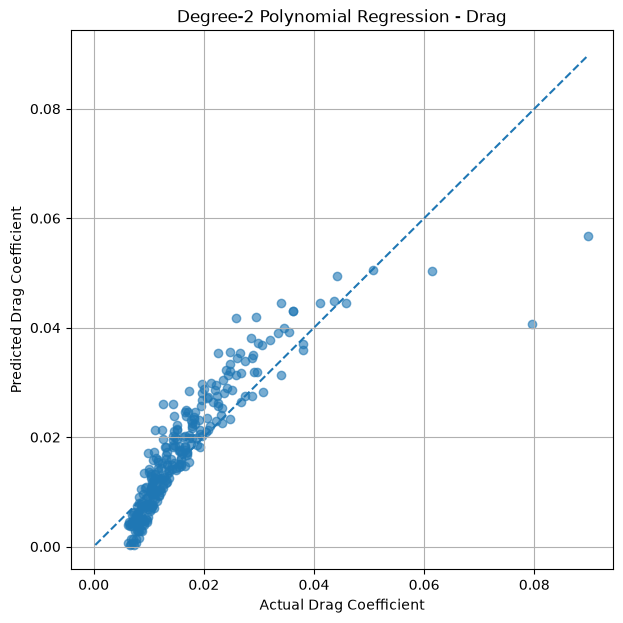

In [19]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_test_CD,
    CD_poly_pred,
    alpha=0.6,
)

minimum = min(
    y_test_CD.min(),
    CD_poly_pred.min(),
)

maximum = max(
    y_test_CD.max(),
    CD_poly_pred.max(),
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
)

plt.xlabel(
    "Actual Drag Coefficient"
)

plt.ylabel(
    "Predicted Drag Coefficient"
)

plt.title(
    "Degree-2 Polynomial Regression - Drag"
)

plt.grid()

plt.show()

In [20]:
cl_poly3_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "poly",
        PolynomialFeatures(
            degree=3,
            include_bias=False,
        ),
    ),
    ("regression", LinearRegression()),
])

cd_poly3_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "poly",
        PolynomialFeatures(
            degree=3,
            include_bias=False,
        ),
    ),
    ("regression", LinearRegression()),
])

cl_poly3_model.fit(
    X_train,
    y_train_CL,
)

cd_poly3_model.fit(
    X_train,
    y_train_CD,
)

CL_poly3_pred = cl_poly3_model.predict(X_test)
CD_poly3_pred = cd_poly3_model.predict(X_test)

print("Degree-3 models trained.")

Degree-3 models trained.


In [21]:
CL_poly3_MAE = mean_absolute_error(
    y_test_CL,
    CL_poly3_pred,
)

CL_poly3_RMSE = np.sqrt(
    mean_squared_error(
        y_test_CL,
        CL_poly3_pred,
    )
)

CL_poly3_R2 = r2_score(
    y_test_CL,
    CL_poly3_pred,
)


CD_poly3_MAE = mean_absolute_error(
    y_test_CD,
    CD_poly3_pred,
)

CD_poly3_RMSE = np.sqrt(
    mean_squared_error(
        y_test_CD,
        CD_poly3_pred,
    )
)

CD_poly3_R2 = r2_score(
    y_test_CD,
    CD_poly3_pred,
)


print("DEGREE-3 POLYNOMIAL RESULTS")
print("----------------------------")

print("\nLift coefficient:")
print(f"MAE  = {CL_poly3_MAE:.5f}")
print(f"RMSE = {CL_poly3_RMSE:.5f}")
print(f"R²   = {CL_poly3_R2:.5f}")

print("\nDrag coefficient:")
print(f"MAE  = {CD_poly3_MAE:.5f}")
print(f"RMSE = {CD_poly3_RMSE:.5f}")
print(f"R²   = {CD_poly3_R2:.5f}")

DEGREE-3 POLYNOMIAL RESULTS
----------------------------

Lift coefficient:
MAE  = 0.02856
RMSE = 0.03930
R²   = 0.99566

Drag coefficient:
MAE  = 0.00338
RMSE = 0.00509
R²   = 0.75584


In [22]:
from sklearn.model_selection import GroupKFold

In [23]:
groups = data["airfoil"]

X_all = data[features]
y_CL_all = data["CL"]
y_CD_all = data["CD"]

group_kfold = GroupKFold(
    n_splits=5
)

results = []

models = {
    "Linear": 1,
    "Polynomial Degree 2": 2,
    "Polynomial Degree 3": 3,
}


for model_name, degree in models.items():

    fold_number = 0

    for train_index, test_index in group_kfold.split(
        X_all,
        y_CL_all,
        groups=groups,
    ):

        fold_number += 1

        X_train_cv = X_all.iloc[train_index]
        X_test_cv = X_all.iloc[test_index]

        y_train_CL_cv = y_CL_all.iloc[train_index]
        y_test_CL_cv = y_CL_all.iloc[test_index]

        y_train_CD_cv = y_CD_all.iloc[train_index]
        y_test_CD_cv = y_CD_all.iloc[test_index]


        if degree == 1:

            cl_cv_model = Pipeline([
                ("scaler", StandardScaler()),
                ("regression", LinearRegression()),
            ])

            cd_cv_model = Pipeline([
                ("scaler", StandardScaler()),
                ("regression", LinearRegression()),
            ])

        else:

            cl_cv_model = Pipeline([
                ("scaler", StandardScaler()),
                (
                    "poly",
                    PolynomialFeatures(
                        degree=degree,
                        include_bias=False,
                    ),
                ),
                ("regression", LinearRegression()),
            ])

            cd_cv_model = Pipeline([
                ("scaler", StandardScaler()),
                (
                    "poly",
                    PolynomialFeatures(
                        degree=degree,
                        include_bias=False,
                    ),
                ),
                ("regression", LinearRegression()),
            ])


        cl_cv_model.fit(
            X_train_cv,
            y_train_CL_cv,
        )

        cd_cv_model.fit(
            X_train_cv,
            y_train_CD_cv,
        )


        CL_cv_pred = cl_cv_model.predict(
            X_test_cv
        )

        CD_cv_pred = cd_cv_model.predict(
            X_test_cv
        )


        results.append({
            "Model": model_name,
            "Fold": fold_number,

            "CL_MAE": mean_absolute_error(
                y_test_CL_cv,
                CL_cv_pred,
            ),

            "CL_RMSE": np.sqrt(
                mean_squared_error(
                    y_test_CL_cv,
                    CL_cv_pred,
                )
            ),

            "CL_R2": r2_score(
                y_test_CL_cv,
                CL_cv_pred,
            ),

            "CD_MAE": mean_absolute_error(
                y_test_CD_cv,
                CD_cv_pred,
            ),

            "CD_RMSE": np.sqrt(
                mean_squared_error(
                    y_test_CD_cv,
                    CD_cv_pred,
                )
            ),

            "CD_R2": r2_score(
                y_test_CD_cv,
                CD_cv_pred,
            ),
        })


cv_results = pd.DataFrame(results)

cv_results

,Model,Fold,CL_MAE,CL_RMSE,CL_R2,CD_MAE,CD_RMSE,CD_R2
0,Linear,1,0.072105,0.093102,0.972936,0.008986,0.012194,0.251221
1,Linear,2,0.078828,0.105802,0.967126,0.006277,0.010914,0.297977
2,Linear,3,0.068629,0.098075,0.973325,0.007418,0.015134,0.190313
3,Linear,4,0.081856,0.102556,0.970422,0.005031,0.006710,0.400249
4,Linear,5,0.062767,0.087422,0.975842,0.006939,0.011301,0.210105
5,Polynomial Degree 2,1,0.038682,0.054242,0.990813,0.005345,0.007786,0.694733
6,Polynomial Degree 2,2,0.046721,0.067089,0.986782,0.004420,0.007610,0.658725
7,Polynomial Degree 2,3,0.050529,0.076291,0.983859,0.005403,0.011777,0.509623
8,Polynomial Degree 2,4,0.044396,0.057437,0.990723,0.004224,0.005631,0.577671
9,Polynomial Degree 2,5,0.048746,0.061874,0.987899,0.005031,0.007220,0.677571


In [24]:
cv_summary = (
    cv_results
    .groupby("Model")
    [
        [
            "CL_MAE",
            "CL_RMSE",
            "CL_R2",
            "CD_MAE",
            "CD_RMSE",
            "CD_R2",
        ]
    ]
    .agg(["mean", "std"])
)

cv_summary

CL_MAE             CL_RMSE               CL_R2  \
                         mean       std      mean       std      mean   
Model                                                                   
Linear               0.072837  0.007696  0.097391  0.007343  0.971930   
Polynomial Degree 2  0.045815  0.004597  0.063387  0.008682  0.988015   
Polynomial Degree 3  0.042156  0.012953  0.058419  0.018770  0.989296   

                                 CD_MAE             CD_RMSE            \
                          std      mean       std      mean       std   
Model                                                                   
Linear               0.003302  0.006930  0.001457  0.011250  0.003029   
Polynomial Degree 2  0.002914  0.004885  0.000537  0.008005  0.002274   
Polynomial Degree 3  0.007088  0.004802  0.000987  0.007452  0.003063   

                        CD_R2            
                         mean       std  
Model                                    
Linear               0.269973  0.083722  
Polynomial Degree 2  0.623664  0.077953  
Polynomial Degree 3  0.673450  0.147579

In [25]:
mean_results = (
    cv_results
    .groupby("Model")
    [
        [
            "CL_MAE",
            "CL_RMSE",
            "CL_R2",
            "CD_MAE",
            "CD_RMSE",
            "CD_R2",
        ]
    ]
    .mean()
)

mean_results

,CL_MAE,CL_RMSE,CL_R2,CD_MAE,CD_RMSE,CD_R2
Model,,,,,,
Linear,0.072837,0.097391,0.971930,0.006930,0.011250,0.269973
Polynomial Degree 2,0.045815,0.063387,0.988015,0.004885,0.008005,0.623664
Polynomial Degree 3,0.042156,0.058419,0.989296,0.004802,0.007452,0.673450
